# BikeFlow
### Predicting Bike Rental Demand in Seoul

1. Introduction

The purpose of this project is to investigate whether machine learning can predict hourly bike rental demand in Seoul based on weather conditions and time-related factors.

The dataset contains 8,760 hourly observations from December 2017 to November 2018.

To enrich the original dataset, historical cloud cover data was collected from the Open-Meteo API and matched to the bike rental observations using date and hour.

### Business question

Can we predict hourly bike rental demand to support better capacity planning?

Machine learning approach

This is a supervised learning problem using regression, since the target variable, Rented Bike Count, is a numerical value.

The project will compare Linear Regression and Random Forest Regressor to evaluate which approach produces more accurate predictions.

In [1]:
import pandas as pd

# Read and enrich our data
df = pd.read_csv("data/bikeflow_enriched.csv")

# Size of data set
print("Dataset shape:", df.shape)

# 5 first rows
display(df.head())

Dataset shape: (8760, 16)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,datetime,cloud_cover
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00,0
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00,0
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00,0


## 2. Data Understanding & Quality Checks

Before cleaning or modeling, we inspect the dataset's structure, data types, and completeness.

In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names, data types and non-null counts
df.info()

Dataset shape: (8760, 16)
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 n

In [3]:

# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Count completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Count duplicated timestamps
print("Duplicate timestamps:", df["datetime"].duplicated().sum())


Missing values per column:
Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
datetime                     0
cloud_cover                  0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0


In [ ]:

# Convert datetime from text (str) to pandas datetime
df["datetime"] = pd.to_datetime(df["datetime"])

# Sort observations chronologically (oldest first). Important due to training modell on the oldest dates.
df = df.sort_values("datetime").reset_index(drop=True)

# Check the data type after conversion
print("Data type:", df["datetime"].dtype)

# Check the first and last timestamps
print("First timestamp:", df["datetime"].min())
print("Last timestamp:", df["datetime"].max())


Data type: datetime64[us]
First timestamp: 2017-12-01 00:00:00
Last timestamp: 2018-11-30 23:00:00


### 2.2 Data Quality Summary

The dataset contains 8,760 hourly observations and 16 columns. No missing values, duplicate rows, or duplicate timestamps were found.

The datetime column is converted to a proper datetime format, and the observations are sorted chronologically to prepare for time series analysis and modeling.

In [5]:

# Create a complete hourly timeline between the first and last timestamp
expected_hours = pd.date_range(
    start=df["datetime"].min(),  # First timestamp in our dataset
    end=df["datetime"].max(),    # Last timestamp in our dataset
    freq="h"                     # One timestamp per hour
)

# Find timestamps that should exist but are missing from the dataset
missing_hours = expected_hours.difference(df["datetime"])

# Display the results
print("Expected hours:", len(expected_hours))
print("Actual rows:", len(df))
print("Missing hours:", len(missing_hours))


Expected hours: 8760
Actual rows: 8760
Missing hours: 0


In [6]:

# Display descriptive statistics for all numerical columns
df.describe().T


,count,mean,min,25%,50%,75%,max,std
Rented Bike Count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
Hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
Temperature(°C),8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
Humidity(%),8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
Wind speed (m/s),8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
Visibility (10m),8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
Dew point temperature(°C),8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
Solar Radiation (MJ/m2),8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
Rainfall(mm),8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193
Snowfall (cm),8760.0,0.075068,0.0,0.0,0.0,0.0,8.8,0.436746


In [7]:

# Count hours with zero bike rentals
print("Zero bike rentals:", (df["Rented Bike Count"] == 0).sum())

# Count hours with zero humidity
print("Zero humidity:", (df["Humidity(%)"] == 0).sum())

# Count hours with rainfall greater than zero
print("Hours with rain:", (df["Rainfall(mm)"] > 0).sum())

# Count hours with snowfall greater than zero
print("Hours with snow:", (df["Snowfall (cm)"] > 0).sum())


Zero bike rentals: 295
Zero humidity: 17
Hours with rain: 528
Hours with snow: 443


In [8]:

# Compare zero rentals with whether the bike rental system was operating
pd.crosstab(
    df["Functioning Day"],        # Rows: operating status (Yes/No)
    df["Rented Bike Count"] == 0,  # Columns: True if rentals equal zero
    margins=True                  # Add totals for rows and columns
)


Rented Bike Count,False,True,All
Functioning Day,,,
No,0,295,295
Yes,8465,0,8465
All,8465,295,8760


### Zero Rentals and Operational Status

A cross-tabulation revealed that all 295 observations with zero bike rentals occurred when the bike rental system was not functioning (`Functioning Day = No`).

The remaining 8,465 observations represent hours when the system was operating, and all have positive rental counts.

Since the objective is to predict rental demand during operating hours, non-functioning periods will be excluded from the modeling dataset. The original dataset will be preserved.

This decision also avoids zero target values when calculating MAPE. However, MAPE will still be interpreted cautiously, particularly for hours with low rental counts.

In [9]:

# Keep the original dataset unchanged
# Select only hours when the rental system was operating
df_model = df[df["Functioning Day"] == "Yes"].copy()

# Check the number of observations
print("Original dataset:", df.shape)
print("Modeling dataset:", df_model.shape)


Original dataset: (8760, 16)
Modeling dataset: (8465, 16)


In [10]:

# Select rows where humidity is exactly zero
zero_humidity = df[df["Humidity(%)"] == 0]

# Display relevant columns to investigate these observations
zero_humidity[
    [
        "datetime",
        "Temperature(°C)",
        "Humidity(%)",
        "Dew point temperature(°C)",
        "Rainfall(mm)",
        "cloud_cover",
        "Functioning Day"
    ]
]


,datetime,Temperature(°C),Humidity(%),Dew point temperature(°C),Rainfall(mm),cloud_cover,Functioning Day
4063,2018-05-19 07:00:00,11.4,0,4.5,0.0,0,Yes
4106,2018-05-21 02:00:00,13.9,0,-2.1,0.0,92,Yes
4107,2018-05-21 03:00:00,13.0,0,-2.5,0.0,27,Yes
4108,2018-05-21 04:00:00,12.4,0,-3.4,0.0,19,Yes
4109,2018-05-21 05:00:00,11.9,0,-2.7,0.0,0,Yes
4110,2018-05-21 06:00:00,11.4,0,-2.0,0.0,0,Yes
4111,2018-05-21 07:00:00,12.3,0,-2.7,0.0,0,Yes
4131,2018-05-22 03:00:00,15.5,0,10.4,0.0,75,Yes
4132,2018-05-22 04:00:00,15.6,0,10.5,0.0,100,Yes
4133,2018-05-22 05:00:00,15.7,0,10.6,0.0,100,Yes


In [ ]:

# Select observations from May 22, between 00:00 and 09:00
humidity_check = df[
    (df["datetime"] >= "2018-05-22 00:00:00") &
    (df["datetime"] <= "2018-05-22 09:00:00")
]

# Compare humidity, temperature and dew point over consecutive hours
humidity_check[
    [
        "datetime",
        "Temperature(°C)",
        "Humidity(%)",
        "Dew point temperature(°C)"
    ]
]


,datetime,Temperature(°C),Humidity(%),Dew point temperature(°C)
4128,2018-05-22 00:00:00,16.0,71,10.7
4129,2018-05-22 01:00:00,15.9,71,10.6
4130,2018-05-22 02:00:00,15.7,74,11.0
4131,2018-05-22 03:00:00,15.5,0,10.4
4132,2018-05-22 04:00:00,15.6,0,10.5
4133,2018-05-22 05:00:00,15.7,0,10.6
4134,2018-05-22 06:00:00,15.5,0,10.4
4135,2018-05-22 07:00:00,16.3,69,10.5
4136,2018-05-22 08:00:00,18.2,63,11.0
4137,2018-05-22 09:00:00,19.3,62,11.8


In [12]:

# Keep the original humidity values for comparison
df_model["Humidity_original"] = df_model["Humidity(%)"]

# Mark suspicious zero humidity values as missing
df_model["Humidity(%)"] = df_model["Humidity(%)"].replace(0, float("nan"))

# Use datetime as a temporary index for time-based interpolation
df_model = df_model.set_index("datetime")

# Estimate missing humidity values using surrounding timestamps
df_model["Humidity(%)"] = df_model["Humidity(%)"].interpolate(method="time")

# Restore datetime as a regular column
df_model = df_model.reset_index()

# Display corrected observations
df_model.loc[
    df_model["Humidity_original"] == 0,
    ["datetime", "Humidity_original", "Humidity(%)"]
]


,datetime,Humidity_original,Humidity(%)
4015,2018-05-19 07:00:00,0,63.500000
4058,2018-05-21 02:00:00,0,30.857143
4059,2018-05-21 03:00:00,0,30.714286
4060,2018-05-21 04:00:00,0,30.571429
4061,2018-05-21 05:00:00,0,30.428571
4062,2018-05-21 06:00:00,0,30.285714
4063,2018-05-21 07:00:00,0,30.142857
4083,2018-05-22 03:00:00,0,73.000000
4084,2018-05-22 04:00:00,0,72.000000
4085,2018-05-22 05:00:00,0,71.000000


In [13]:

# Check whether any humidity values are still missing
print("Missing humidity values:", df_model["Humidity(%)"].isna().sum())

# Check the minimum and maximum humidity after interpolation
print("Minimum humidity:", df_model["Humidity(%)"].min())
print("Maximum humidity:", df_model["Humidity(%)"].max())

# Check that the original dataset is unchanged
print("Zero humidity values in original data:", (df["Humidity(%)"] == 0).sum())


Missing humidity values: 0
Minimum humidity: 10.0
Maximum humidity: 98.0
Zero humidity values in original data: 17


### Humidity Data Quality

Seventeen observations contained zero relative humidity, all occurring in May 2018. Comparison with nearby observations and dew point temperatures indicated that these values were likely recording errors.

The suspicious values were replaced with missing values and estimated using time-based interpolation for exploratory analysis. The original dataset was preserved.

Because time-based interpolation can use future observations, the preprocessing approach will be reviewed before cross-validation and final model evaluation to prevent data leakage.

## 3. Exploratory Data Analysis (EDA)

The purpose of EDA is to understand the distribution of bike rentals, identify patterns and relationships between variables, and investigate potential outliers before training machine learning models.

### 3.1 Distribution of Bike Rentals

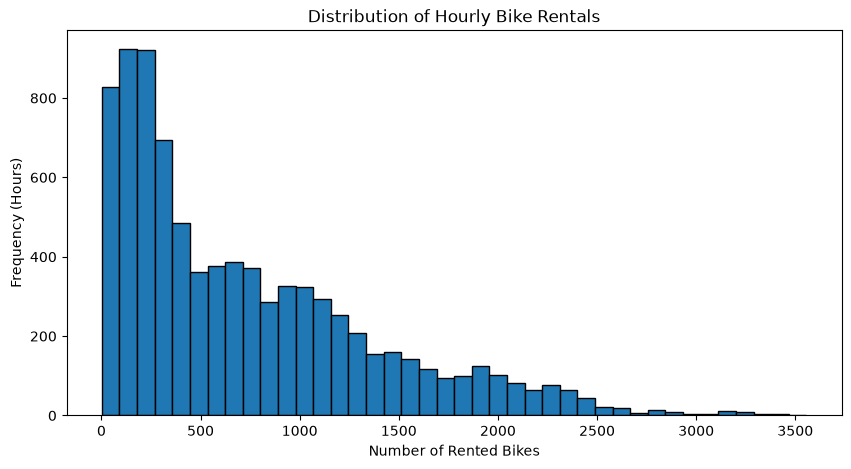

In [ ]:

# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Create a histogram of hourly bike rentals
plt.figure(figsize=(10, 5))

# Divide rental counts into 40 intervals (bins) 89 ish bikes per bin
plt.hist(df_model["Rented Bike Count"], bins=40, edgecolor="black")

# Add chart title and axis labels
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Number of Rented Bikes")
plt.ylabel("Frequency (Hours)")

# Display the chart
plt.show()


/var/folders/87/4p21wf8x54z_3r2h977m5ps00000gn/T/ipykernel_13993/3753461780.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_model["Rented Bike Count"], vert=False)


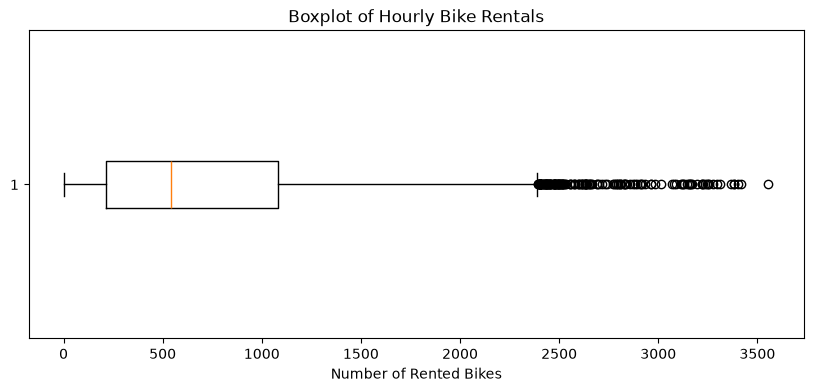

In [15]:

# Create a boxplot to examine the distribution and potential outliers
plt.figure(figsize=(10, 4))

# Show the distribution of hourly bike rentals
plt.boxplot(df_model["Rented Bike Count"], vert=False)

# Add a title and label
plt.title("Boxplot of Hourly Bike Rentals")
plt.xlabel("Number of Rented Bikes")

# Display the chart
plt.show()


In [16]:

# Select the 10 hours with the highest number of bike rentals
top_rentals = df_model.nlargest(10, "Rented Bike Count")

# Display relevant columns to investigate high-demand hours
top_rentals[
    [
        "datetime",
        "Rented Bike Count",
        "Hour",
        "Temperature(°C)",
        "Rainfall(mm)",
        "Seasons",
        "Holiday"
    ]
]


,datetime,Rented Bike Count,Hour,Temperature(°C),Rainfall(mm),Seasons,Holiday
4770,2018-06-19 18:00:00,3556,18,24.1,0.0,Summer,No Holiday
4818,2018-06-21 18:00:00,3418,18,27.8,0.0,Summer,No Holiday
4602,2018-06-12 18:00:00,3404,18,24.9,0.0,Summer,No Holiday
4794,2018-06-20 18:00:00,3384,18,27.0,0.0,Summer,No Holiday
4410,2018-06-04 18:00:00,3380,18,24.4,0.0,Summer,No Holiday
4842,2018-06-22 18:00:00,3365,18,29.3,0.0,Summer,No Holiday
4506,2018-06-08 18:00:00,3309,18,26.2,0.0,Summer,No Holiday
6762,2018-09-10 18:00:00,3298,18,25.9,0.0,Autumn,No Holiday
6930,2018-09-17 18:00:00,3277,18,25.3,0.0,Autumn,No Holiday
6810,2018-09-12 18:00:00,3256,18,27.0,0.0,Autumn,No Holiday


### 3.3 Average Bike Rentals by Hour

We investigate how average bike rental demand varies throughout the day to identify possible daily patterns and peak hours.

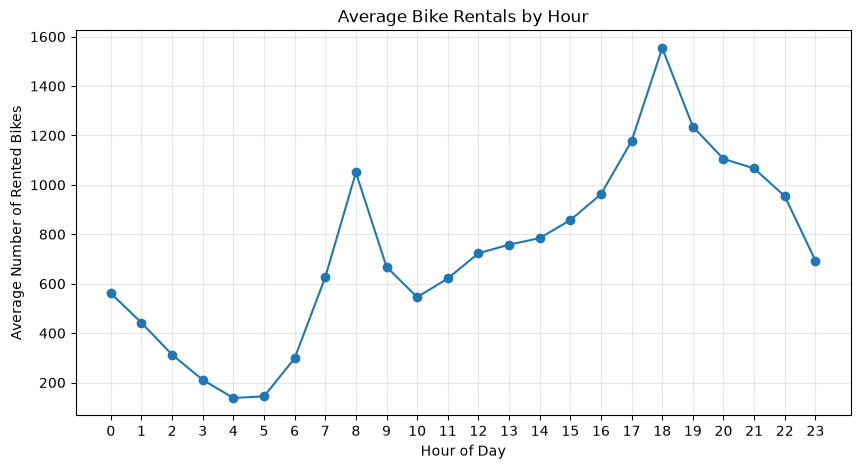

In [18]:

# Calculate average bike rentals for each hour of the day
hourly_rentals = df_model.groupby("Hour")["Rented Bike Count"].mean()

# Create a line chart
plt.figure(figsize=(10, 5))

# Plot the average rentals for each hour
plt.plot(hourly_rentals.index, hourly_rentals.values, marker="o")

# Add chart title and axis labels
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rented Bikes")

# Show every hour on the X-axis
plt.xticks(range(24))

# Add a grid to make the chart easier to read
plt.grid(alpha=0.3)

# Display the chart
plt.show()


In [17]:
df_model.groupby("Hour")["Rented Bike Count"].mean()

Hour
0      561.457386
1      441.923295
2      312.769886
3      210.840909
4      137.488636
5      144.218750
6      298.184659
7      626.606232
8     1050.229462
9      667.943343
10     545.764873
11     621.277620
12     723.218130
13     758.172805
14     784.620397
15     857.373938
16     962.257790
17    1177.212465
18    1554.016997
19    1235.776204
20    1105.303116
21    1066.512748
22     954.167139
23     693.940510
Name: Rented Bike Count, dtype: float64

**EDA Finding – Hourly Rental Patterns**

Average bike rental demand shows two distinct peaks: one at 08:00 and a larger peak at 18:00. The lowest demand occurs around 04:00–05:00.

This pattern may be associated with morning and evening commuting. Demand also increases gradually during the afternoon before reaching its highest level at 18:00.

These findings suggest that the hour of the day is an important potential predictor of bike rental demand.

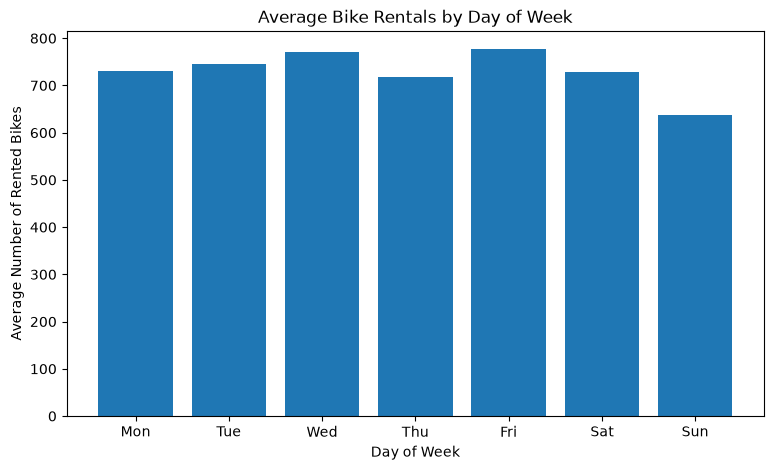

In [19]:

# Extract the day of the week from datetime
# Monday = 0, Tuesday = 1, ..., Sunday = 6
df_model["day_of_week"] = df_model["datetime"].dt.dayofweek

# Calculate average rentals for each day of the week
daily_rentals = df_model.groupby("day_of_week")["Rented Bike Count"].mean()

# Create a bar chart
plt.figure(figsize=(9, 5))

# Display average rentals for Monday through Sunday
plt.bar(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    daily_rentals.reindex(range(7))
)

# Add title and labels
plt.title("Average Bike Rentals by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Rented Bikes")

# Display the chart
plt.show()
